In [2]:
%pip install -q kaggle py7zr pandas pillow tqdm scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, shutil, zipfile, py7zr

# copy kaggle.json to ~/.kaggle
src = os.path.expanduser("~/Downloads/kaggle.json")
dst_dir = os.path.expanduser("~/.kaggle")
os.makedirs(dst_dir, exist_ok=True)
if not os.path.exists(os.path.join(dst_dir, "kaggle.json")) and os.path.exists(src):
    shutil.copy2(src, dst_dir)

# download (skipped if already downloaded)
if not os.path.exists("cifar-10.zip"):
    get_ipython().system("kaggle competitions download -c cifar-10")

# extract (skipped if already extracted)
DATA = "cifar10_data"
os.makedirs(DATA, exist_ok=True)
if not os.path.exists(f"{DATA}/trainLabels.csv"):
    with zipfile.ZipFile("cifar-10.zip") as z:
        z.extractall(DATA)

def find_train_dir():
    for d in (f"{DATA}/train/train", f"{DATA}/train"):
        if os.path.exists(f"{d}/1.png"):
            return d

if find_train_dir() is None:
    with py7zr.SevenZipFile(f"{DATA}/train.7z") as a:
        a.extractall(DATA)

TRAIN_DIR = find_train_dir()
print("Images folder:", TRAIN_DIR, "| files:", len(os.listdir(TRAIN_DIR)))

Images folder: cifar10_data/train/train | files: 50000


In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

df = pd.read_csv(f"{DATA}/trainLabels.csv")
y = df["label"].map(CLASSES.index).values

if os.path.exists("cifar10_arrays.npz"):            # cache so re-runs are fast
    X = np.load("cifar10_arrays.npz")["X"]
else:
    X = np.stack([np.asarray(Image.open(f"{TRAIN_DIR}/{i}.png").convert("RGB")) for i in tqdm(df["id"])])
    np.savez_compressed("cifar10_arrays.npz", X=X)

print(X.shape, y.shape)
print(df["label"].value_counts().to_string())

(50000, 32, 32, 3) (50000,)
label
frog          5000
truck         5000
deer          5000
automobile    5000
bird          5000
horse         5000
ship          5000
cat           5000
dog           5000
airplane      5000


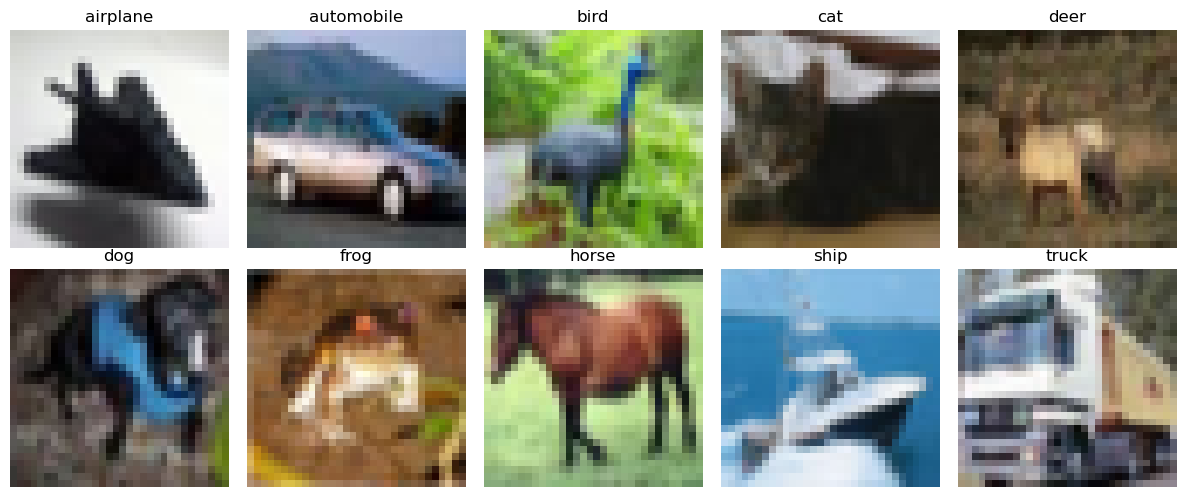

In [5]:
# Show one image per class
plt.figure(figsize=(12, 5))
for k, name in enumerate(CLASSES):
    plt.subplot(2, 5, k + 1)
    plt.imshow(X[np.where(y == k)[0][0]])
    plt.title(name)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [6]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

idx = np.arange(len(X))
tv, te = train_test_split(idx, test_size=0.1, stratify=y, random_state=42)
tr, va = train_test_split(tv, test_size=1/9, stratify=y[tv], random_state=42)

x_train, y_train = preprocess_input(X[tr].astype("float32")), y[tr]
x_val,   y_val   = preprocess_input(X[va].astype("float32")), y[va]
x_test,  y_test  = preprocess_input(X[te].astype("float32")), y[te]
print("train", x_train.shape, "| val", x_val.shape, "| test", x_test.shape)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (CPU training will be slow)")

train (40000, 32, 32, 3) | val (5000, 32, 32, 3) | test (5000, 32, 32, 3)
GPU: none (CPU training will be slow)


In [7]:
IMG = 96

base = ResNet50(include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
base.trainable = False

model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Resizing(IMG, IMG),
    layers.RandomFlip("horizontal"),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        20,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,608,202 (90.06 MB)

 Trainable params: 20,490 (80.04 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [8]:
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=5, batch_size=64)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 515s 809ms/step - accuracy: 0.7696 - loss: 0.8138 - val_accuracy: 0.8398 - val_loss: 0.5261
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 547s 785ms/step - accuracy: 0.8252 - loss: 0.5700 - val_accuracy: 0.8494 - val_loss: 0.4746
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 780s 1s/step - accuracy: 0.8361 - loss: 0.5368 - val_accuracy: 0.8448 - val_loss: 0.5000
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 661s 1s/step - accuracy: 0.8401 - loss: 0.5239 - val_accuracy: 0.8530 - val_loss: 0.4740
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 521s 802ms/step - accuracy: 0.8454 - loss: 0.5078 - val_accuracy: 0.8556 - val_loss: 0.4677


In [9]:
base.trainable = True
for layer in base.layers:                      # keep BatchNorm frozen for stable fine-tuning
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=5, batch_size=64)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 2290s 4s/step - accuracy: 0.8941 - loss: 0.3105 - val_accuracy: 0.9190 - val_loss: 0.2389
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1953s 3s/step - accuracy: 0.9354 - loss: 0.1884 - val_accuracy: 0.9244 - val_loss: 0.2299
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1634s 3s/step - accuracy: 0.9564 - loss: 0.1267 - val_accuracy: 0.9306 - val_loss: 0.2147
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1610s 3s/step - accuracy: 0.9694 - loss: 0.0871 - val_accuracy: 0.9364 - val_loss: 0.2108
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1407s 2s/step - accuracy: 0.9787 - loss: 0.0635 - val_accuracy: 0.9356 - val_loss: 0.2088


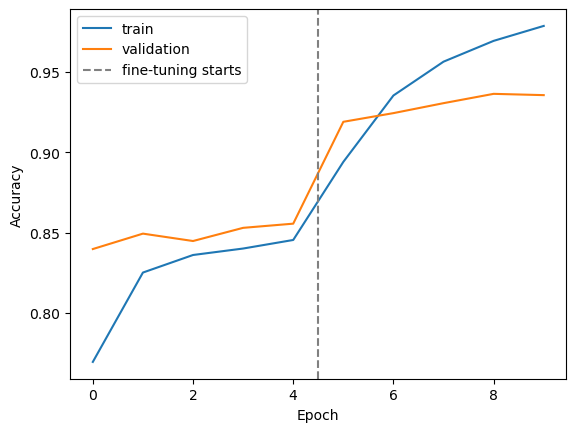

Test accuracy: 0.9376

              precision    recall  f1-score   support

    airplane       0.96      0.94      0.95       500
  automobile       0.97      0.96      0.96       500
        bird       0.95      0.92      0.93       500
         cat       0.88      0.87      0.88       500
        deer       0.92      0.95      0.93       500
         dog       0.88      0.90      0.89       500
        frog       0.95      0.98      0.97       500
       horse       0.94      0.92      0.93       500
        ship       0.99      0.96      0.97       500
       truck       0.95      0.98      0.96       500

    accuracy                           0.94      5000
   macro avg       0.94      0.94      0.94      5000
weighted avg       0.94      0.94      0.94      5000



In [10]:
acc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
tracc = h1.history["accuracy"] + h2.history["accuracy"]
plt.plot(tracc, label="train")
plt.plot(acc, label="validation")
plt.axvline(len(h1.history["accuracy"]) - 0.5, color="gray", linestyle="--", label="fine-tuning starts")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.show()

loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}\n")

pred = model.predict(x_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, pred, target_names=CLASSES))

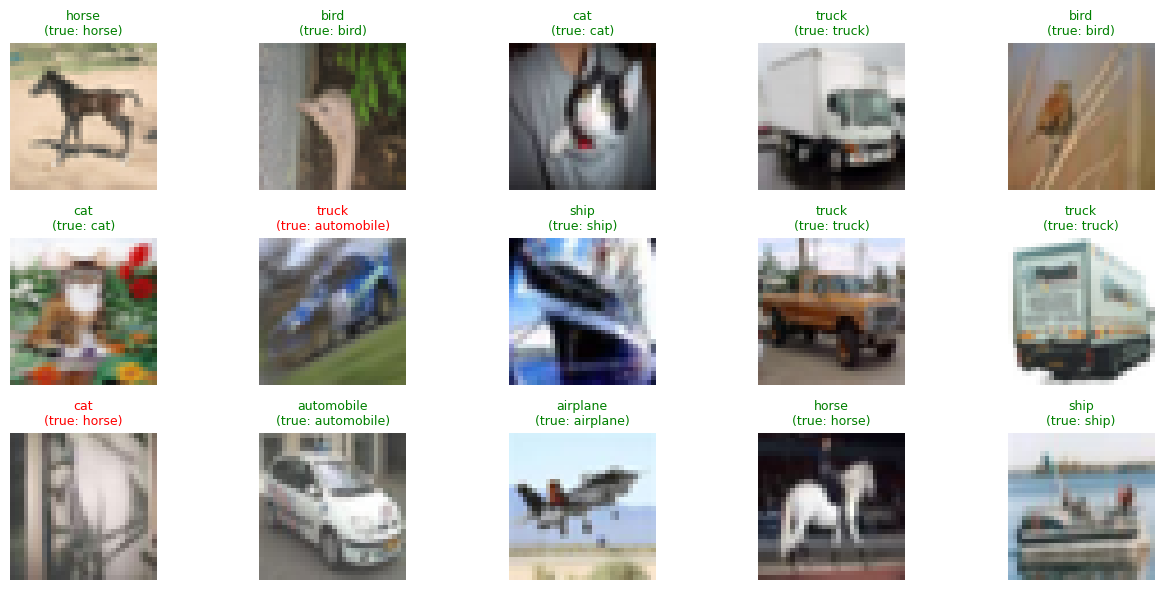

Model saved: cifar10_resnet50.keras


In [11]:
# Sample predictions (green = correct, red = wrong)
plt.figure(figsize=(13, 6))
for k, i in enumerate(range(15)):
    plt.subplot(3, 5, k + 1)
    plt.imshow(X[te][i])
    plt.title(f"{CLASSES[pred[i]]}\n(true: {CLASSES[y_test[i]]})", fontsize=9,
              color="green" if pred[i] == y_test[i] else "red")
    plt.axis("off")
plt.tight_layout()
plt.show()

model.save("cifar10_resnet50.keras")
print("Model saved: cifar10_resnet50.keras")